In [23]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 30

# t_final = 1.0e-4
t_final = 1.0e-4

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.995

ion_density = 1.0e20
ion_velocity = 0
ion_temperature = 1

K_cx = 3.2e-15 * np.sqrt(ion_temperature/0.026)
collision_rate = K_cx * ion_density

BGK_stddev = np.sqrt(ion_temperature * 1.602176634e-19 / 1.67e-27)

D = BGK_stddev**2 / collision_rate


print('Collision rate: ', collision_rate)
print('Average collision time: ', 1/collision_rate)

print('Expected deviation: ', np.sqrt(2*D*t_final))
print('99.9 range: ', 2 * 2.6 * np.sqrt(2*D*t_final))
print(x)

Collision rate:  1984555.7534273353
Average collision time:  5.038911092686594e-07
Expected deviation:  0.0983287021620305
99.9 range:  0.5113092512425587
[0.         0.03333333 0.06666667 0.1        0.13333333 0.16666667
 0.2        0.23333333 0.26666667 0.3        0.33333333 0.36666667
 0.4        0.43333333 0.46666667 0.5        0.53333333 0.56666667
 0.6        0.63333333 0.66666667 0.7        0.73333333 0.76666667
 0.8        0.83333333 0.86666667 0.9        0.93333333 0.96666667
 1.        ]


In [24]:
# simulate using monte carlo

n_cells_mc = 300
n_particles = 10000
density_mc = np.zeros(n_cells_mc, dtype=float)
x_mc = np.linspace(0, 1, n_cells_mc+1)
x_center_mc = 0.5 * (x_mc[:-1] + x_mc[1:])
for i in range(n_particles):
    x_particle = x0
    t = 0
    v = np.random.normal(ion_velocity, BGK_stddev)

    while t < t_final:
        # time till next collision
        eps = np.random.rand()
        tc = -np.log(eps) / collision_rate
        tc = min(tc, t_final - t)

        # calculate time till boundary hit
        t_boundary = np.inf
        if v > 0:
            t_boundary = (1 - x_particle) / v
        elif v < 0:
            t_boundary = x_particle / -v

        if t_boundary < tc:
            # move particle to boundary
            x_particle += v * t_boundary
            v = -v
            t += t_boundary
            continue

        # move particle
        x_particle += v * tc
        # draw new velocity
        v = np.random.normal(ion_velocity, BGK_stddev)
        t += tc

    # tally final position
    x_index = int(x_particle * n_cells_mc)
    volume = 1/(n_cells_mc)
    density_mc[x_index] += 1/volume / n_particles

In [25]:
# simulate using backward euler
dt = t_final / 10
r = D * dt / h**2

# matrix A for implicit method
A = np.zeros((n_cells, n_cells)) 
A[0, 0] = 1 + r
A[0, 1] = -r
A[-1, -1] = 1 + r
A[-1, -2] = -r
for i in range(1, n_cells-1):
    A[i, i] = 1 + 2 * r
    A[i, i-1] = -r
    A[i, i+1] = -r

density_fluid = np.zeros(n_cells)

x_index = int(x0 * n_cells)
density_fluid[x_index] = n_cells

# x_index_left = math.floor(x0 * n_cells)
# x_index_right = math.ceil(x0 * n_cells)
# if x_index_left == x_index_right:
#     weight_left = 0
#     weight_right = 1
# else:
#     weight_left = x_index_right - x0 * n_cells
#     weight_right = x0 * n_cells - x_index_left

# print('x_index_left: ', x_index_left)
# print('x_index_right: ', x_index_right)
# print('weight_left: ', weight_left)
# print('weight_right: ', weight_right)

# density_fluid[x_index_left] = n_cells * weight_left
# density_fluid[x_index_right] = n_cells * weight_right

print('Initial density: ', density_fluid)

# density_fluid = np.linalg.solve(A, density_fluid)

for t in np.arange(0, t_final, dt):
    density_fluid = np.linalg.solve(A, density_fluid)

print('Final density: ', density_fluid)

Initial density:  [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 30.]
Final density:  [1.59765715e-10 3.90081955e-10 1.17295940e-09 3.58836252e-09
 1.09097283e-08 3.28666235e-08 9.80252210e-08 2.89231322e-07
 8.43601161e-07 2.43016565e-06 6.90748786e-06 1.93516351e-05
 5.33699541e-05 1.44695927e-04 3.85046015e-04 1.00388695e-03
 2.55902936e-03 6.36276916e-03 1.53882620e-02 3.60819335e-02
 8.17100610e-02 1.77892942e-01 3.70302505e-01 7.32138871e-01
 1.36388729e+00 2.37063494e+00 3.79933802e+00 5.53597427e+00
 7.21791021e+00 8.28820192e+00]


In [26]:
# Analytical model

density_analytical = np.zeros(n_cells)

# calculate reflection coefficient so that flux is zero at x = 1
R = 1

for i in range(n_cells):
    x_center = (i + 0.5) / n_cells
    density_analytical[i] = np.exp( -( x_center - x0 )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final) + R * np.exp( -( x_center + x0 - 2 )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final)

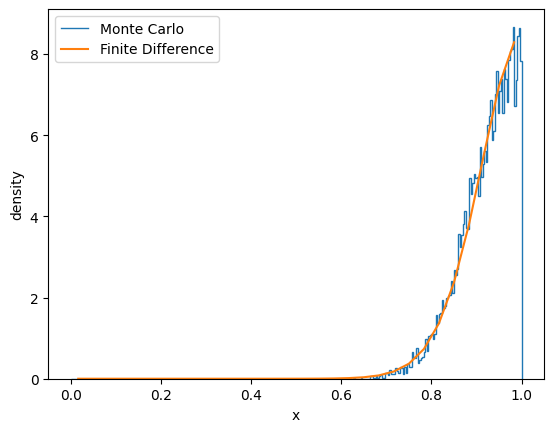

In [27]:

x_center = 0.5 * (x[:-1] + x[1:])

plt.stairs(density_mc, x_mc, label='Monte Carlo')
# plt.stairs(density_fluid, x, label='Finite Difference')
# plt.stairs(density_analytical, x, label='Analytical')
plt.plot(x_center, density_fluid, label='Finite Difference')
# plt.plot(x_center, density_analytical, label='Analytical')
plt.legend()
plt.xlabel('x')
plt.ylabel('density')
plt.show()